In [8]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from technical import technical_init, summary
from sentiment import sentiment_init, Sentiment_result
from datetime import datetime
import yfinance as yf
import sqlite3
import pickle

In [9]:
with open("model/model.pkl", "rb") as file:
    model = pickle.load(file)

class MarketState(TypedDict):
    ticker: str
    verdict: summary
    volatility: int
    sentiment: Sentiment_result
    human_decsion: Literal["Hold", "Buy", "Sold"]

In [ ]:
def human_decision_node(state: MarketState):
    try:
        ticker = state["ticker"].upper() + ".NS"
        decision = input("Enter your decision in (Hold, Buy, Sell) ").strip().upper()

        if decision not in ("HOLD", "BUY", "SELL"):
            raise ValueError("choose from the give option")

        if decision == "BUY":
            history = yf.Ticker(ticker).history(period="5d")
            if history.empty or history.dropna().empty:
                raise ValueError(f"No stock price data available for {ticker}")
            
            price = float(history["Close"].dropna().iloc[-1])
            reason = input("Enter the your reason to BUY")

            conn = sqlite3.connect("investment.db")
            conn.execute(
                """Insert into investments
                   ("ticker", "decision", "entry_price", "entry_date", "reasoning")
                   values(?, ?, ?, ?, ?)
                """,(
                    ticker, decision, price, datetime.now().isoformat(), reason, price
                )
            )

        conn.commit()
        conn.close()
        return {"decision": decision}

    except ValueError as e:
        print(e)

    except ConnectionError as e:
        print(f"cannot connect to the database")

In [16]:
def collection(state: MarketState):
    ticker = input("Enter the Stock")
    return {"ticker": ticker}

def technode(state: MarketState):
    ticker = state["ticker"]
    result = technical_init(ticker)
    return {"verdict": result}

def sentimentnode(state: MarketState):
    ticker = state["ticker"]
    result = sentiment_init(ticker)
    return {"sentiment": result}

def output(state: MarketState):
    ans = state["verdict"].Position
    return {"result": ans}

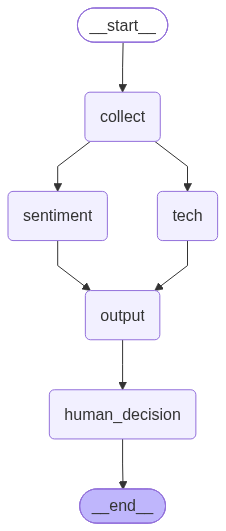

In [17]:
graph = StateGraph(MarketState)

graph.add_node("tech", technode)
graph.add_node("sentiment", sentimentnode)
graph.add_node("collect", collection)
graph.add_node("output", output)
graph.add_node("human_decision", human_decision_node)

graph.add_edge(START, "collect")
graph.add_edge("collect", "sentiment")
graph.add_edge("collect", "tech")

graph.add_edge("tech", "output")
graph.add_edge("sentiment", "output")
graph.add_edge("output", "human_decision")
graph.add_edge("human_decision", END)

graph.compile()

In [18]:
workflow = graph.compile()

In [19]:
initial_state = {}
result = workflow.invoke(initial_state)

Searching news for RELIANCE... 
getting the dataset...



[*********************100%***********************]  1 of 1 completed


getting the signals...
Done

getting summary...
Finding the final sentiment 



Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2143.67it/s]


summarising news 1
summarising news 2
summarising news 3


$RELIANCE: No data found, symbol may be delisted


No stock price data available for RELIANCE
